In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import utils

In [2]:
df = pd.read_csv("ej1/Life-Expectancy-Data-Updated.csv")

In [3]:
df = df.rename(columns={"Economy_status_Developed": "Developed"})
df = df.drop(columns='Economy_status_Developing')

In [4]:
data_2015 = df[df['Year'] == 2015]

In [ ]:
data_2015.head()

In [6]:
data = data_2015.drop(columns=['Country', 'Year', 'Region'])
countries = data_2015['Country']

In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
features_scaled = scaler.fit_transform(data)

<h3>Inciso a

Number of clusters: 1


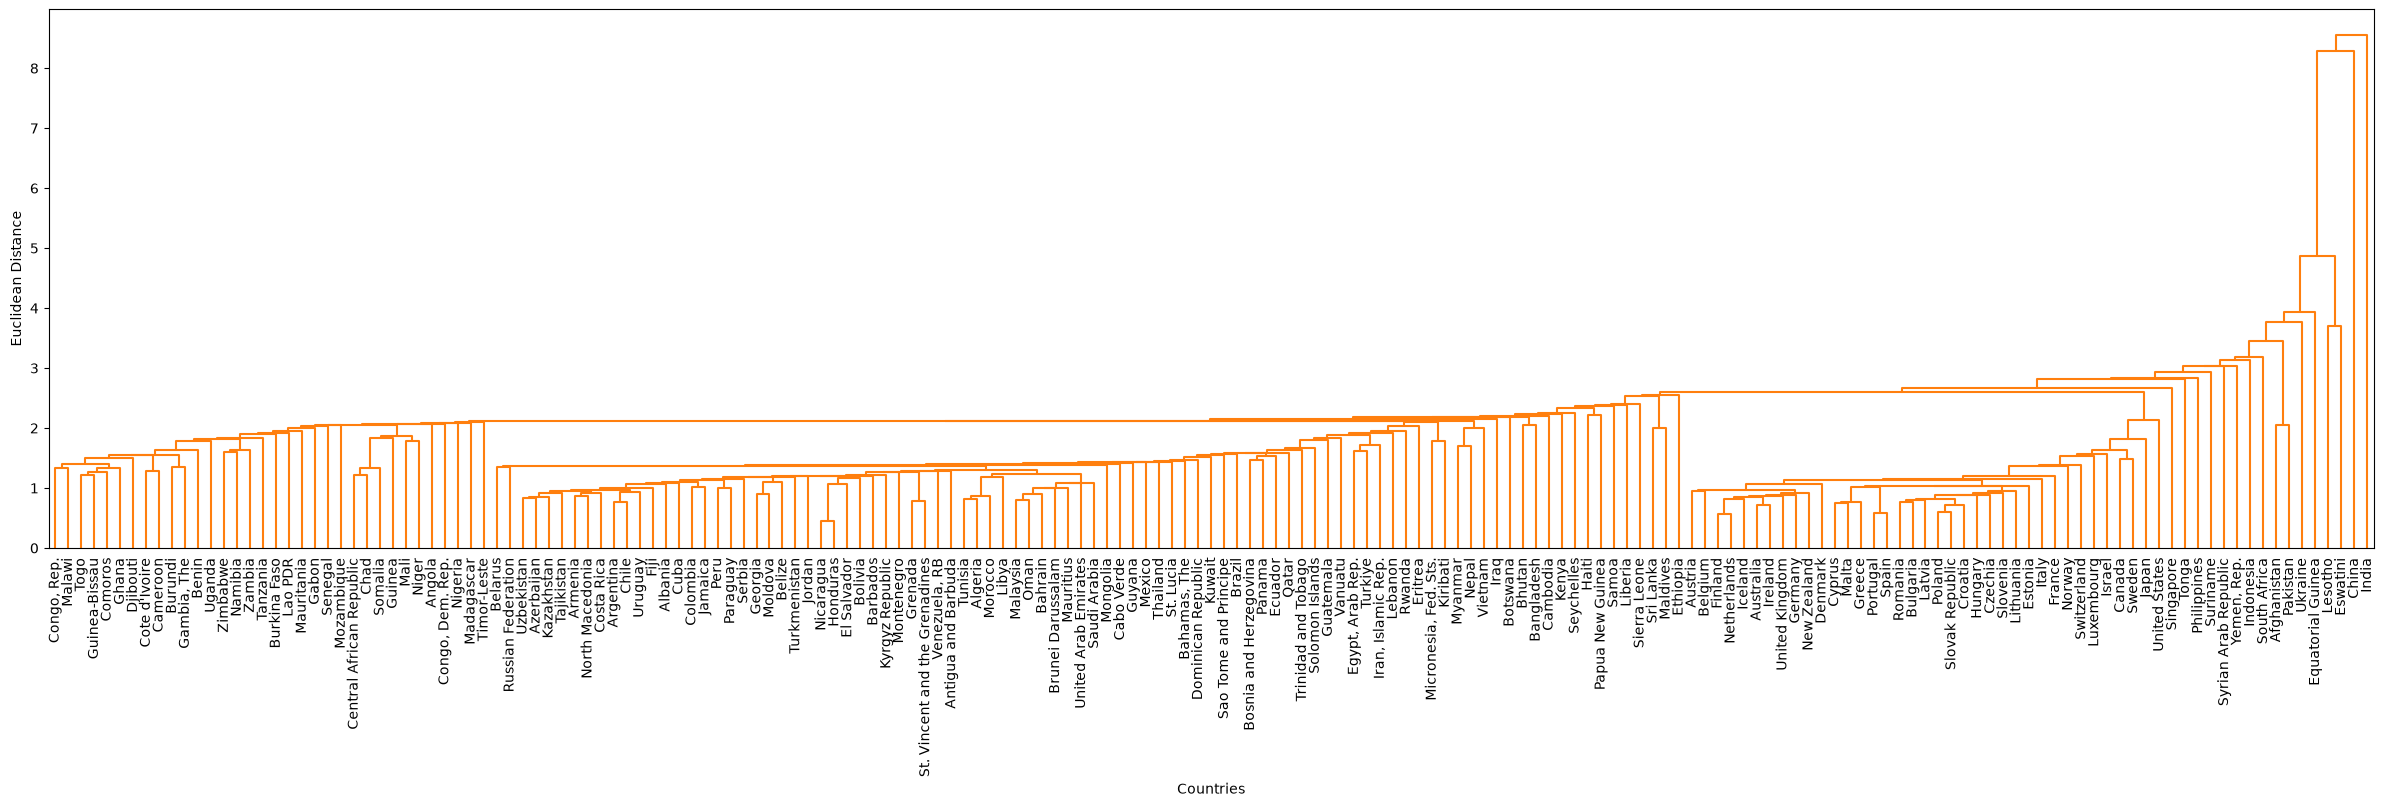

In [22]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

t=5500

# generamos el clustering jerárquico
linked = linkage(features_scaled, metric="euclidean", method='single')

clusters = fcluster(linked, t=t, criterion='distance')
print(f"Number of clusters: {len(set(clusters))}")

# ploteamos el dendrograma
plt.figure(figsize=(30,7))
dendrogram(
    linked,
    orientation='top',
    labels=list(countries), # ojo que hay que pasarle una lista
    distance_sort='descending',
    show_leaf_counts=True,
    leaf_font_size=10,
    above_threshold_color='blue',
    color_threshold=t
)
plt.xlabel('Countries')
plt.ylabel('Euclidean Distance')
plt.axhline(y=t, color='red', linestyle='--')
plt.show()

<h3>Inciso b

In [23]:
from itertools import count

from sklearn.cluster import AgglomerativeClustering

agglomerative = AgglomerativeClustering(n_clusters=3, metric="euclidean", linkage='single')
clusters_agglomerative3 = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=4, metric="euclidean", linkage='single')
clusters_agglomerative4 = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=5, metric="euclidean", linkage='single')
clusters_agglomerative5 = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=6, metric="euclidean", linkage='single')
clusters_agglomerative6 = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=7, metric="euclidean", linkage='single')
clusters_agglomerative7 = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=8, metric="euclidean", linkage='single')
clusters_agglomerative8  = agglomerative.fit_predict(features_scaled)

# for k in np.unique(clusters_agglomerative4):
#   print('Cluster {}'.format(k))
#   print(countries[clusters_agglomerative4==k])
#   print('======')

3 Clusters
DB score: 0.3584
Silhouette score: 0.4941
-------------
4 Clusters
DB score: 0.4842
Silhouette score: 0.4421
-------------
5 Clusters
DB score: 0.4657
Silhouette score: 0.3878
-------------
6 Clusters
DB score: 0.4654
Silhouette score: 0.3397
-------------
7 Clusters
DB score: 0.4050
Silhouette score: 0.3183
-------------
8 Clusters
DB score: 0.4621
Silhouette score: 0.2546
-------------


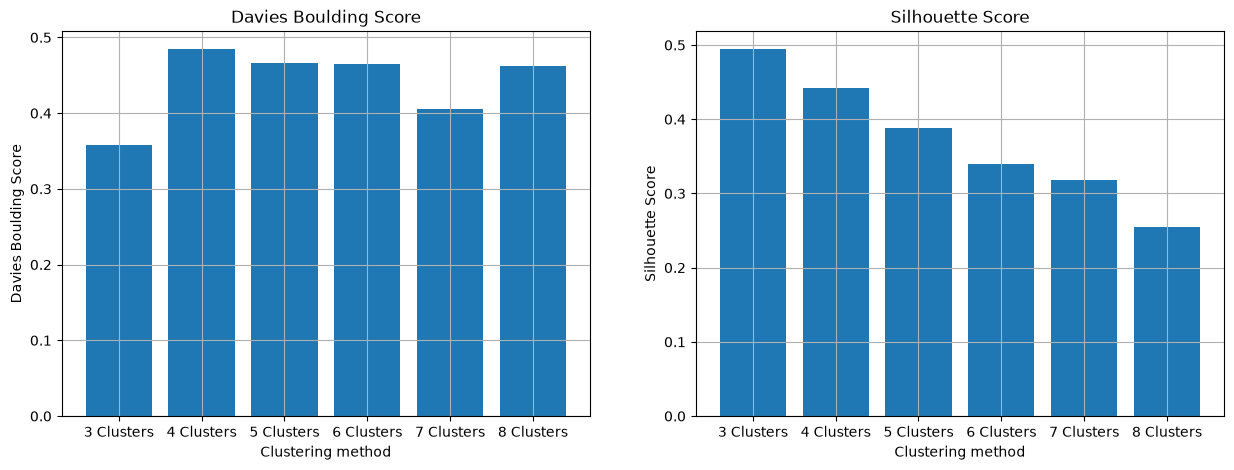

In [24]:
from sklearn.metrics import davies_bouldin_score, silhouette_score

clusters_to_compare = [clusters_agglomerative3, clusters_agglomerative4, clusters_agglomerative5, clusters_agglomerative6, clusters_agglomerative7, clusters_agglomerative8]
clustering_methods = ['3 Clusters', '4 Clusters', '5 Clusters', '6 Clusters', '7 Clusters', '8 Clusters']

db_scores = np.zeros(len(clusters_to_compare))
silhouette_scores = np.zeros(len(clusters_to_compare))

for i in range(len(clusters_to_compare)):
    #calculamos metricas
    db_scores[i] = davies_bouldin_score(features_scaled, clusters_to_compare[i])
    silhouette_scores[i] = silhouette_score(features_scaled, clusters_to_compare[i])

    print(clustering_methods[i])
    print('DB score: {:,.4f}'.format(db_scores[i]))
    print('Silhouette score: {:.4f}'.format(silhouette_scores[i]))
    print('-------------')

# inicializamos un gráfico para cada métrica
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# graficamos el Davies Bouldin score -- cuanto mas bajo mejor
axes[0].bar(np.arange(db_scores.size), db_scores)
axes[0].set_title('Davies Boulding Score')
axes[0].set_xlabel('Clustering method')
axes[0].set_ylabel('Davies Boulding Score')
axes[0].set_xticks(np.arange(db_scores.size))
axes[0].set_xticklabels(clustering_methods, rotation=0)
axes[0].grid(True)

# y el Silhouette Score -- cuanto mas alto mejor
axes[1].bar(np.arange(silhouette_scores.size), silhouette_scores)
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Clustering method')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(np.arange(silhouette_scores.size))
axes[1].set_xticklabels(clustering_methods, rotation=0)
axes[1].grid(True)

plt.show()

A partir de las metricas, el mas correcto es el de 4 clusters ya que representa el valor mas bajo de Davies Boulding y es el tercer mejor posicionado en el puntaje de silueta.

<h3>Inciso c

Number of clusters: 4


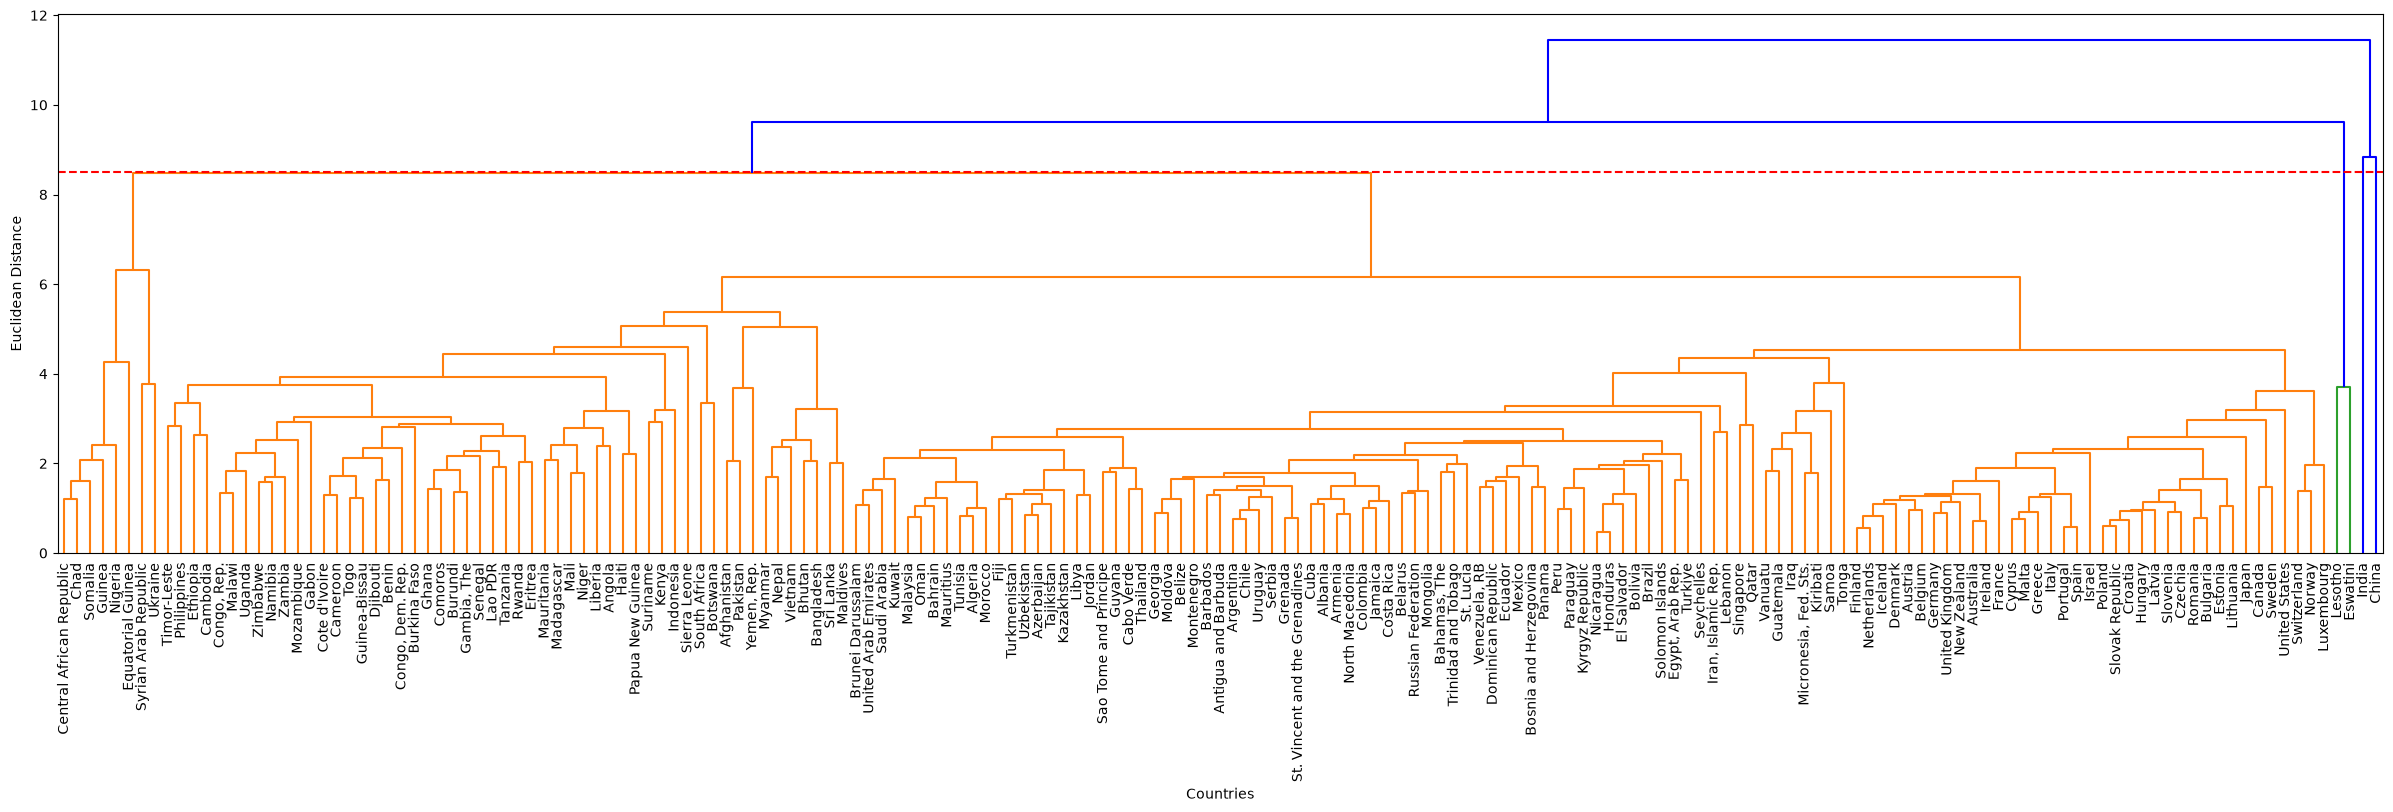

In [33]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

t=8.5

# generamos el clustering jerárquico
linked = linkage(features_scaled, metric="euclidean", method='average')

clusters = fcluster(linked, t=t, criterion='distance')
print(f"Number of clusters: {len(set(clusters))}")

# ploteamos el dendrograma
plt.figure(figsize=(30,7))
dendrogram(
    linked,
    orientation='top',
    labels=list(countries), # ojo que hay que pasarle una lista
    distance_sort='descending',
    show_leaf_counts=True,
    leaf_font_size=10,
    above_threshold_color='blue',
    color_threshold=t
)
plt.xlabel('Countries')
plt.ylabel('Euclidean Distance')
plt.axhline(y=t, color='red', linestyle='--')
plt.show()

In [27]:
from itertools import count

from sklearn.cluster import AgglomerativeClustering

agglomerative = AgglomerativeClustering(n_clusters=3, metric="euclidean", linkage='average')
clusters_agglomerative3 = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=4, metric="euclidean", linkage='average')
clusters_agglomerative4 = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=5, metric="euclidean", linkage='average')
clusters_agglomerative5 = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=6, metric="euclidean", linkage='average')
clusters_agglomerative6 = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=7, metric="euclidean", linkage='average')
clusters_agglomerative7 = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=8, metric="euclidean", linkage='average')
clusters_agglomerative8  = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=9, metric="euclidean", linkage='average')
clusters_agglomerative9  = agglomerative.fit_predict(features_scaled)
    
agglomerative = AgglomerativeClustering(n_clusters=10, metric="euclidean", linkage='average')
clusters_agglomerative10  = agglomerative.fit_predict(features_scaled)

agglomerative = AgglomerativeClustering(n_clusters=11, metric="euclidean", linkage='average')
clusters_agglomerative11  = agglomerative.fit_predict(features_scaled)

3 Clusters
DB score: 0.7511
Silhouette score: 0.4585
-------------
4 Clusters
DB score: 0.4842
Silhouette score: 0.4421
-------------
5 Clusters
DB score: 0.5951
Silhouette score: 0.3945
-------------
6 Clusters
DB score: 0.5710
Silhouette score: 0.3373
-------------
7 Clusters
DB score: 0.7150
Silhouette score: 0.3459
-------------
8 Clusters
DB score: 0.7804
Silhouette score: 0.3435
-------------
9 Clusters
DB score: 0.8091
Silhouette score: 0.3205
-------------
10 Clusters
DB score: 0.7649
Silhouette score: 0.3070
-------------
11 Clusters
DB score: 0.7480
Silhouette score: 0.2869
-------------


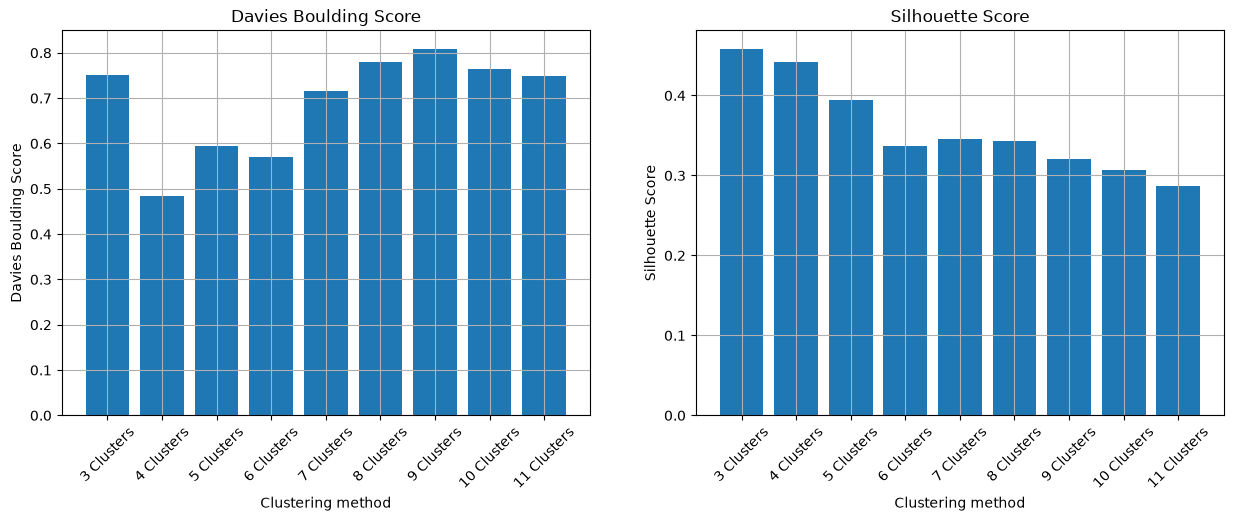

In [28]:
from sklearn.metrics import davies_bouldin_score, silhouette_score


clusters_to_compare = [
    clusters_agglomerative3,
    clusters_agglomerative4,
    clusters_agglomerative5,
    clusters_agglomerative6,
    clusters_agglomerative7,
    clusters_agglomerative8,
    clusters_agglomerative9,
    clusters_agglomerative10,
    clusters_agglomerative11
]
clustering_methods = [
    '3 Clusters',
    '4 Clusters',
    '5 Clusters',
    '6 Clusters',
    '7 Clusters',
    '8 Clusters',
    '9 Clusters',
    '10 Clusters',
    '11 Clusters'
]

db_scores = np.zeros(len(clusters_to_compare))
silhouette_scores = np.zeros(len(clusters_to_compare))

for i in range(len(clusters_to_compare)):
    #calculamos metricas
    db_scores[i] = davies_bouldin_score(features_scaled, clusters_to_compare[i])
    silhouette_scores[i] = silhouette_score(features_scaled, clusters_to_compare[i])

    print(clustering_methods[i])
    print('DB score: {:,.4f}'.format(db_scores[i]))
    print('Silhouette score: {:.4f}'.format(silhouette_scores[i]))
    print('-------------')

# inicializamos un gráfico para cada métrica
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# graficamos el Davies Bouldin score -- cuanto mas bajo mejor
axes[0].bar(np.arange(db_scores.size), db_scores)
axes[0].set_title('Davies Boulding Score')
axes[0].set_xlabel('Clustering method')
axes[0].set_ylabel('Davies Boulding Score')
axes[0].set_xticks(np.arange(db_scores.size))
axes[0].set_xticklabels(clustering_methods, rotation=45)
axes[0].grid(True)

# y el Silhouette Score -- cuanto mas alto mejor
axes[1].bar(np.arange(silhouette_scores.size), silhouette_scores)
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Clustering method')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(np.arange(silhouette_scores.size))
axes[1].set_xticklabels(clustering_methods, rotation=45)
axes[1].grid(True)

plt.show()

In [30]:
from sklearn.cluster import KMeans
def clusterizar(k, data):
    kmeans = KMeans(n_clusters=k, verbose=0, random_state=10)
    kmeans.fit(data)
    return kmeans.predict(data)

In [70]:
cluster_df = pd.DataFrame({'Country': countries, 'Cluster': clusterizar(4, features_scaled)})
cluster_index = cluster_df.set_index('Country')['Cluster']
data_2015['Cluster'] = data_2015['Country'].map(cluster_index)
for cluster_num in range(4):
    print(f"\nCluster {cluster_num}:")
    print(cluster_df[cluster_df['Cluster'] == cluster_num]['Country'].tolist())


Cluster 0:
['Ukraine', 'Iraq', 'Indonesia', 'Kiribati', 'Syrian Arab Republic', 'Panama', 'Lebanon', 'Guatemala', 'Micronesia, Fed. Sts.', 'Papua New Guinea', 'Vanuatu', 'Cambodia', 'Suriname', 'Philippines', 'Ecuador', 'Samoa']

Cluster 1:
['Spain', 'Norway', 'Latvia', 'Israel', 'New Zealand', 'Sweden', 'Czechia', 'Canada', 'Lithuania', 'Netherlands', 'Bulgaria', 'Portugal', 'Finland', 'Slovenia', 'Belgium', 'Japan', 'Slovak Republic', 'Austria', 'Malta', 'Greece', 'Ireland', 'Croatia', 'Switzerland', 'United Kingdom', 'Germany', 'Denmark', 'Poland', 'Italy', 'Hungary', 'Australia', 'Luxembourg', 'United States', 'Cyprus', 'Iceland', 'Estonia', 'Romania', 'France']

Cluster 2:
['Turkiye', 'Russian Federation', 'Algeria', 'Oman', 'Vietnam', 'Belarus', 'Costa Rica', 'Solomon Islands', 'Honduras', 'Dominican Republic', 'Mexico', 'St. Vincent and the Grenadines', 'Brazil', 'Guyana', 'China', 'Kuwait', 'Grenada', 'Albania', 'Saudi Arabia', 'Turkmenistan', 'Antigua and Barbuda', 'Seychelle

In [74]:
cluster_kmeans = clusterizar(4, features_scaled)
df_cluster = data_2015.drop(columns=['Year', 'Region']).copy()
df_cluster['Cluster'] = cluster_kmeans
#df_cluster = pd.DataFrame({'Country': countries, 'Cluster': cluster_kmeans})

df_cluster

,Country,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,Polio,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Developed,Life_expectancy,Cluster
0,Turkiye,11.1,13.0,105.8240,1.32,97,65,27.8,97,97,0.08,11006,78.53,4.9,4.8,7.8,0,76.5,2
1,Spain,2.7,3.3,57.9025,10.35,97,94,26.0,97,97,0.09,25742,46.44,0.6,0.5,9.7,1,82.8,1
6,Russian Federation,6.6,8.2,223.0000,8.06,97,97,26.2,97,97,0.08,9313,144.10,2.3,2.3,12.0,0,71.2,2
27,Cameroon,57.0,88.0,340.1265,4.55,84,64,24.3,77,84,1.12,1383,23.30,5.6,5.5,6.1,0,57.6,3
43,"Gambia, The",39.7,59.8,261.7065,2.69,97,64,23.9,96,97,0.96,661,2.09,7.3,7.2,3.4,0,60.9,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2753,Tunisia,14.8,17.2,91.3430,1.50,98,98,26.3,98,98,0.04,4095,11.18,6.5,6.4,7.0,0,75.9,2
2820,"Venezuela, RB",16.4,19.1,141.5540,6.21,87,83,26.7,87,87,0.40,17318,30.08,1.6,1.5,10.1,0,72.6,2
2840,Djibouti,54.6,65.8,251.7490,0.32,84,82,24.0,84,84,0.22,2653,0.91,5.6,5.4,4.1,0,64.1,3
2846,Nicaragua,16.6,19.4,148.4805,3.72,98,83,27.2,99,98,0.11,2050,6.22,1.8,1.7,6.5,0,73.6,2


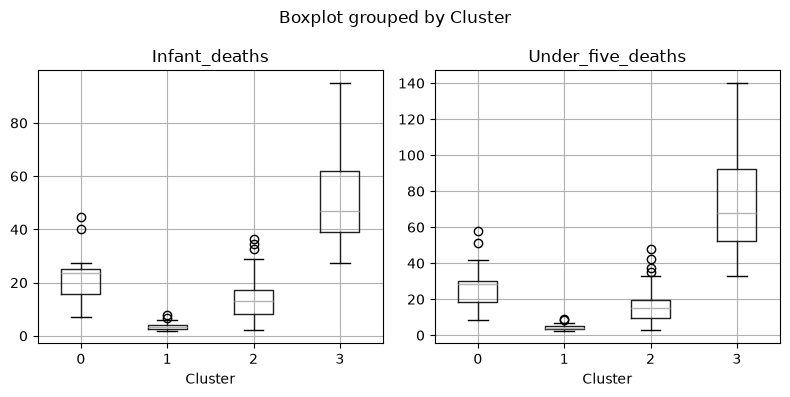

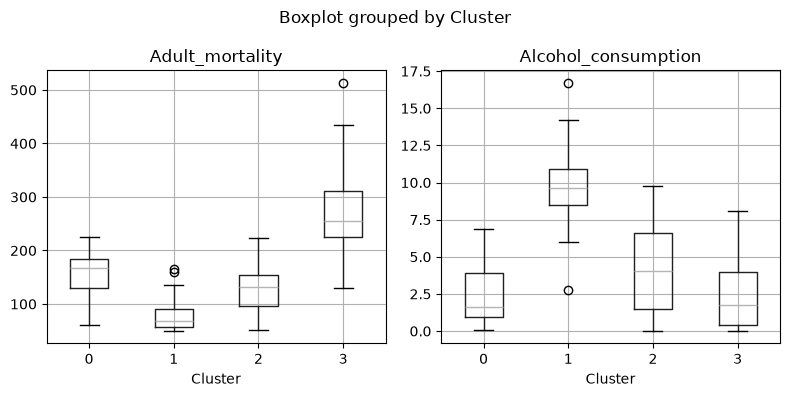

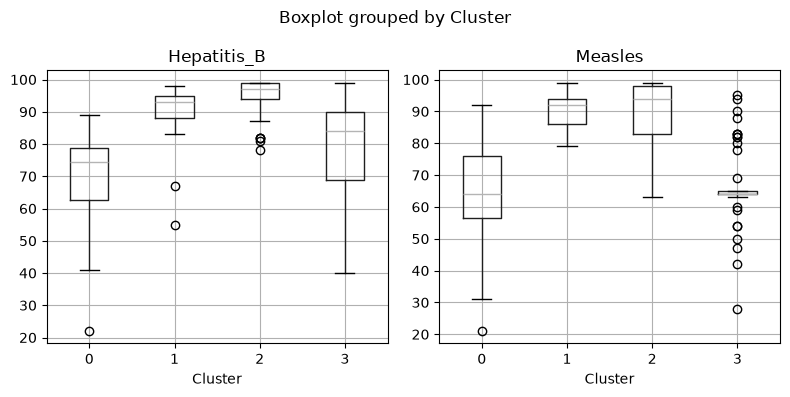

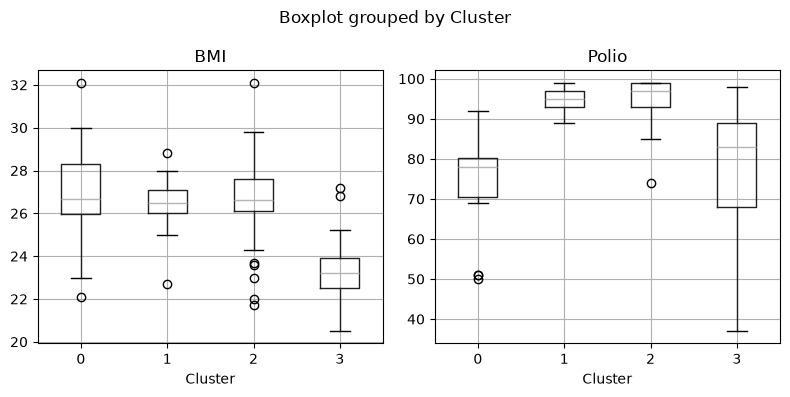

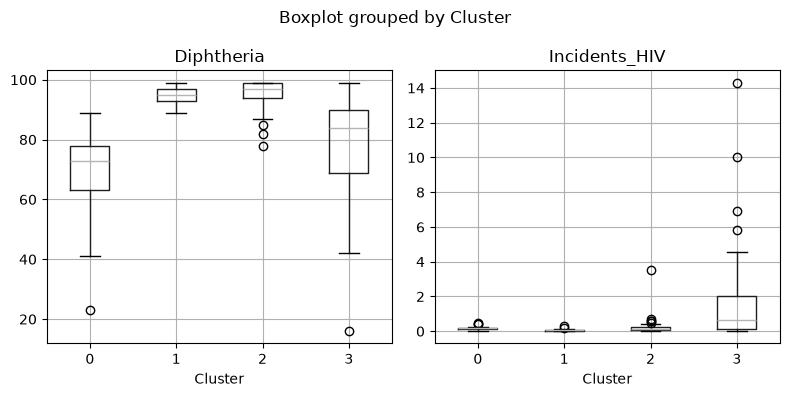

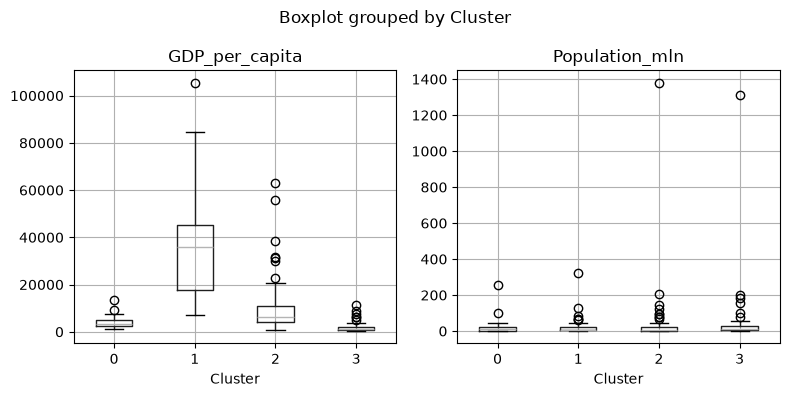

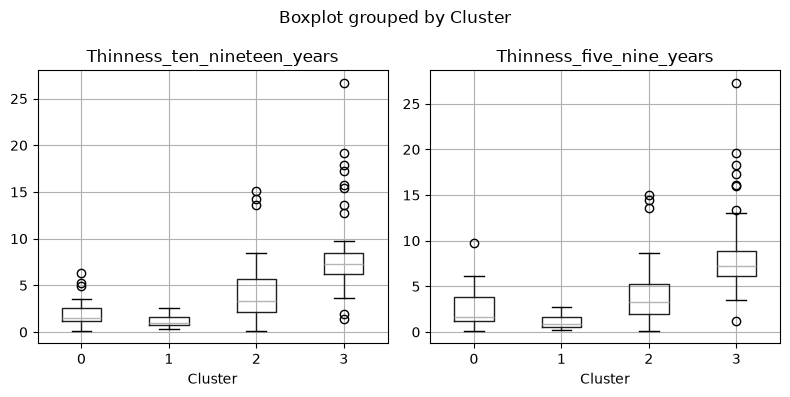

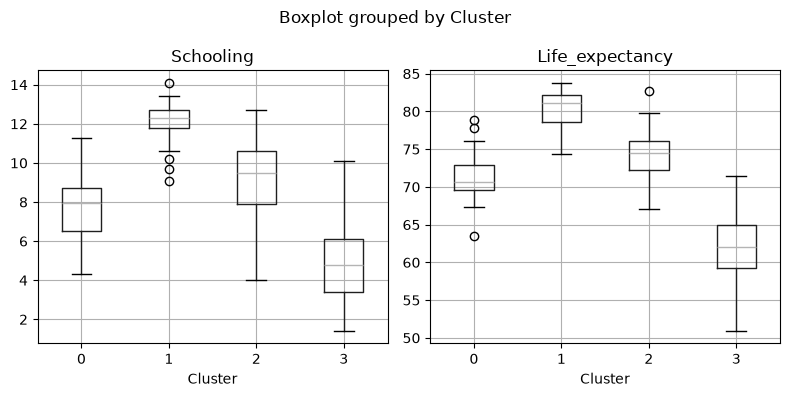

In [69]:
cols = df_cluster.drop(columns=['Cluster', 'Developed']).columns.to_list()

for i in range(0, len(cols), 2):
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))

    for j in range(2):
        if i + j < len(cols):
            col = cols[i + j]
            df_cluster.boxplot(column=col, by='Cluster', ax=ax[j])

    plt.tight_layout()
    plt.show()

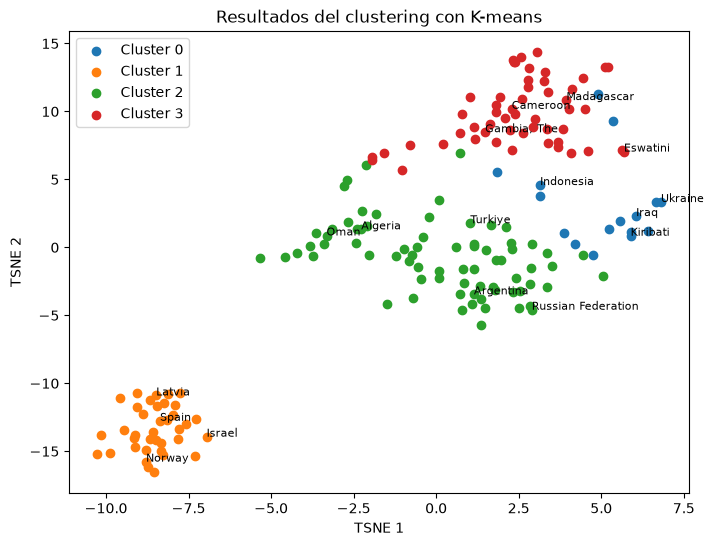

In [75]:
from cProfile import label
from tarfile import data_filter
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(features_scaled)
k  = 4
cluster_kmeans = clusterizar(k, features_scaled)

tsne_df = pd.DataFrame({'x': tsne_results[:, 0], 'y': tsne_results[:, 1], 'Cluster': cluster_kmeans, 'Country': countries})

plt.figure(figsize=(8, 6))
for cluster_num in range(k):
    plt.scatter(tsne_df[tsne_df['Cluster'] == cluster_num]['x'], tsne_df[tsne_df['Cluster'] == cluster_num]['y'], label=f'Cluster {cluster_num}')

    #seleccionar 5 paises a mostrar
    countries_to_label = tsne_df[tsne_df['Cluster'] == cluster_num]['Country'].tolist()
    if 'Argentina' in countries_to_label:
        countries_to_label.remove('Argentina')
        countries_to_label = ['Argentina'] + countries_to_label[:4]
    else:
        countries_to_label = countries_to_label[:4]

    #mostrar los paises
    for country in countries_to_label:
        row = tsne_df[(tsne_df['Cluster'] == cluster_num) & (tsne_df['Country'] == country)]
        if not row.empty:
            plt.text(row['x'].values[0], row['y'].values[0], country, fontsize=8)

plt.xlabel('TSNE 1')
plt.ylabel('TSNE 2')
plt.legend()
plt.title('Resultados del clustering con K-means')
plt.show()

Podemos ver que

- Para las muertes infantibles podemos ver grandes diferencias entre paises desarrollados (Cluster 1) y entre los subdesarrollados (Clusters 0, 2 y 3) el grupo 3 es que se diferencia por encima del resto, superando por crecedad la mediana.

- Para las muertes adultas ocurre lo mismo pero en este caso vemos como los paises desarrollados presentan un incremento en su distribucion a comparacion las muertes infantiles

- Podemos ver como los paises desarrollados (Cluster 1) son los que presentan una distribucion de consumo de alcohol mas elevado en comparacion al resto, donde los paises del grupo 0 y 3 (mayoritariamente africanos) presentan los indices mas bajos.

- Para la cobertura de Hepatitis B podemos como los paises del grupo 1 y 2 son los que presentan una mejor cobertura y una distribucion estable en comparacion a los paises del grupo 0 y 3 que se ubican por encima del 70% de coberturta en media, pero contienen una varianza alta.

- Para la cobertura de Measles podemos ver algo similar en los grupos 1 y 0, pero en el grupo 2 presentamos una mayor variacion de cobertura, oscilando entre 60% y 100%, mientras que el cluster 3, presenta una variacion minima estable en 65% pero con outliers a lo largo de toda la linea de cobertura.

- Para el PBI per capita podemos ver como los paises desarrollados presentan la mediana mas alta pero tambien con una varianza alta donde tenemos que el minimo del grupo es igual a la mediana del grupo 2. Por otro lado vemos como los paises subdesarrollados de los grupos 0 y 3 presentan PBI per capita bajos en comparacion al resto con una varianza minima.

- Para la escolaridad podemos ver como existen diferencias entre todos los grupos

El grupo 0 se ubica como el tercer grupo con mejor escolaridad diferenciandose con creces del grupo 3, donde vemos que el promedio de anios se ubica como mediana en los 8 anios pero varia desde 4 a 11 anios.

Luego, el grupo 1 se ubica con la mediana de escolaridad mas alta (12 anios) variando desde 11 a 13 anios y donde sus outliers mas bajos son comparables a la mediana del grupo 2.

Luego, el grupo 2 es aquel que su promedio de anios en escolaridad se ubica en los 9 anios presentnado una variacion desde 4 a 13 anios (mas alta). A su vez, sus valores minimos de escolaridad son comparables con la mediana del grupo 3 donde el 25% de las observaciones más altas del grupo 3 (su cuartil superior) se solapa con la mitad inferior de la distribución del grupo 2.